# Regional Balloon–Windkessel BOLD with the C++ hybrid backend

The `BalloonWindkessel` monitor turns a regional hybrid simulation into a
simulated fMRI signal. It is the fractional **BOLD change of the balloon
model** (ΔS/S from Friston et al. 2000 and the revised readout of Stephan et
al. 2007), *not* the HRF convolution that the classic `Bold` monitor applies
to a neural time series. If you want the HRF-convolved `Bold` signal of
classic TVB, see `simulate_hybrid_stochastic_and_bold`; `monitor="bold"` and
every existing HRF `Bold` code path are unchanged by anything shown here.

Supported profile at this baseline: one regional subnetwork, one neural
clock and mode, SIMD width one, and a **global** monitor (local BW Recorders
are not available yet). The hemodynamics stay independent per region; the
one shared nominal parameter set is applied to every region's own state.
`backend="cpp"` raises ImportError when the environment has no compiled
extension, so no separate availability check is needed here.

**What you'll learn**

- how to attach `BalloonWindkessel` next to a `TemporalAverage` monitor
- the complete 10 ms held-drive windows and the midpoint output timestamps
- how to calibrate the explicit drive (`drive_baseline`, `drive_scale`)
- why incomplete trailing windows are never emitted
- what a sustained regional BOLD response looks like over 40 simulated seconds

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tvb.simulator import integrators
from tvb.simulator.hybrid import NetworkSet, Simulator, Subnetwork
from tvb.simulator.models.linear import Linear
from tvb.simulator.monitors import BalloonWindkessel, TemporalAverage

#: Neural step in ms. It must divide the monitor's 10 ms drive window exactly;
#: `BalloonWindkessel` rejects any clock the native tick grid cannot represent.
DT = 0.5
#: Regions relax with their own time constants, so the three BOLD traces differ.
GAMMA = np.array([-1e-4, -2e-4, -4e-4])  # 1/ms -> 10 s, 5 s, 2.5 s
INITIAL = np.array([[1.0, 1.0, 1.0]])[..., None]  # (nvar, nnodes, modes)
#: Resting observation and the declared drive in s^-2 per observation unit.
DRIVE_BASELINE = 0.0
DRIVE_SCALE = 0.5

<environment>/test-env/lib/python3.12/site-packages/tvb/simulator/hybrid/__init__.py:165: UserWarning: Hybrid simulation is experimental: please report bugs or suggestions.
  warnings.warn(msg)
<environment>/test-env/lib/python3.12/site-packages/tvb/datatypes/surfaces.py:60: UserWarning: Geodesic distance module is unavailable; some functionality for surfaces will be unavailable.
  warnings.warn(msg)


## 1. Network and drive calibration

The neural model is deliberately simple and deterministic: one state variable
per region relaxing as `dx/dt = gamma * x`. That keeps the observed VOI (and
therefore the calibrated drive) analytically checkable, so the monitor's
timing and calibration can be verified rather than eyeballed.

The monitor does not read raw state or coupling channels. It averages the
observed VOI over each complete 10 ms window, and forms

$$\text{drive}(t) = (\text{window mean} - \text{drive\_baseline}) \times \text{drive\_scale} \quad [s^{-2}]$$

Both calibration numbers are explicit and must be finite; this baseline has
no fitted population values and no per-region parameter lowering. Here the
resting observation is 0, and one unit of the observed VOI above rest is
declared to be `0.5 s⁻²` of balloon inflow drive — a nominal calibration
chosen so the traces below are readable, not a measured physiological value.

In [2]:
def build_network():
    """One three-region subnetwork with a deterministic relaxing neural model."""
    model = Linear(gamma=GAMMA)
    scheme = integrators.EulerDeterministic(dt=DT)
    subnet = Subnetwork(name="regions", model=model, scheme=scheme, nnodes=3,
                        node_indices=np.arange(3))
    return NetworkSet(subnets=[subnet]).configure()


def run_cpp(simulation_length, monitors):
    """Run the public hybrid `Simulator` on the C++ backend.

    Returns one ``(times, data)`` pair per monitor, in the order given.
    """
    sim = Simulator(nets=build_network(), monitors=monitors, backend="cpp",
                    simulation_length=simulation_length)
    sim.configure()
    return sim.run(initial_conditions=[INITIAL.copy()])


def balloon_windkessel(period=20.0, baseline=DRIVE_BASELINE, scale=DRIVE_SCALE):
    """Global regional BW monitor: one observed VOI, explicit drive mapping."""
    return BalloonWindkessel(period=period, variables_of_interest=np.array([0]),
                             drive_baseline=baseline, drive_scale=scale)

## 2. Complete windows and midpoint timestamps

A 200 ms run contains twenty complete 10 ms drive windows, and a 20 ms output
period groups them into ten released rows. The `TemporalAverage` monitor with
the same period reports the same grid, and both stamp a row with the
**midpoint** of the window it summarises: 10, 30, …, 190 ms. The BW row
averages the right-endpoint fractional BOLD values over its whole output
period; there is no initial or trailing partial sample and no shift of the
drive phase.

In [3]:
tavg_t, tavg_x = run_cpp(200.0, [TemporalAverage(period=20.0)])[0]
bw_t, bw_x = run_cpp(200.0, [balloon_windkessel(period=20.0)])[0]

midpoints = 20.0 * np.arange(1, 11) - 10.0
np.testing.assert_array_equal(tavg_t, midpoints)
np.testing.assert_array_equal(bw_t, midpoints)
assert tavg_x.shape == bw_x.shape == (10, 1, 3, 1), (tavg_x.shape, bw_x.shape)
assert np.isfinite(bw_x).all()

print("midpoint times (ms):", bw_t)
print("BW fractional BOLD, last row:", bw_x[-1, 0, :, 0])

midpoint times (ms): [ 10.  30.  50.  70.  90. 110. 130. 150. 170. 190.]
BW fractional BOLD, last row: [-1.45084832e-05 -1.44308015e-05 -1.42773406e-05]


## 3. Incomplete tails are never emitted

Only driving windows that close inside the run are consumed, and only whole
output periods are released. Shortening the run to 195 ms leaves one complete
10 ms window that closes at 190 ms, but that window alone does not fill a
20 ms output period — so the result has nine rows instead of ten, and the
leftover neural ticks are simply discarded.

In [4]:
tail_t, tail_x = run_cpp(195.0, [balloon_windkessel(period=20.0)])[0]
np.testing.assert_array_equal(tail_t, midpoints[:-1])
np.testing.assert_array_equal(bw_t[:len(tail_t)], tail_t)  # same prefix grid
assert tail_x.shape == (9, 1, 3, 1), tail_x.shape

print("195 ms run emits", len(tail_t), "of", len(bw_t), "rows;",
      "last", tail_t[-1], "ms (the incomplete tail is dropped)")

195 ms run emits 9 of 10 rows; last 170.0 ms (the incomplete tail is dropped)


## 4. Checking the calibration

Two independent checks make the driving signal concrete.

First, calibration is exactly a mapping of the observation: with
`drive_scale = 0.0` every window mean maps to zero drive, the balloon state
never leaves its rest point, and the fractional BOLD change is exactly `0.0`
for every region and every row — not merely small.

Second, the drive the monitor integrates is the 10 ms window mean of the
observed VOI, offset and scaled. A `TemporalAverage(period=10.0)` exposes that
same window mean on the same native accumulator, and the closed form of this
model's relaxation predicts it to within a sample-level timing tolerance.

In [5]:
rest_t, rest_x = run_cpp(200.0, [balloon_windkessel(period=20.0, scale=0.0)])[0]
assert not np.any(rest_x), "zero drive must leave the balloon exactly at rest"
print("zero drive -> fractional BOLD is exactly", rest_x.flat[0], "everywhere")

drive_t, drive_x = run_cpp(200.0, [TemporalAverage(period=10.0)])[0]
observed_mean = drive_x[:, 0, :, 0]                            # (windows, regions)
drive = (observed_mean - DRIVE_BASELINE) * DRIVE_SCALE          # s^-2, per region
assert drive.shape == (20, 3), drive.shape

# Closed form: post-step samples of dx/dt = gamma*x at t = (20k + j) * DT.
ticks = np.arange(1, 21)
window_mean = np.exp(GAMMA[None, :] * (DT * ticks)[:, None]).mean(axis=0)  # k = 0
analytic = DRIVE_SCALE * window_mean[None, :] * np.exp(
    GAMMA[None, :] * (20.0 * DT * np.arange(20))[:, None])
np.testing.assert_allclose(drive, analytic, rtol=1e-3)

print("10 ms window means (first 3 windows, region 0):", observed_mean[:3, 0])
print("calibrated drive [s^-2], same windows:", drive[:3, 0])

zero drive -> fractional BOLD is exactly 0.0 everywhere
10 ms window means (first 3 windows, region 0): [0.9994751 0.9984761 0.9974781]
calibrated drive [s^-2], same windows: [0.49973756 0.49923804 0.49873906]


## 5. A regional BOLD response over 40 simulated seconds

Three regions relax with 10 s, 5 s and 2.5 s time constants from the same
initial activation, and the monitor is sampled every 1 s (a 1000 ms period is
100 complete 10 ms drive windows, so the output rows stay complete windows).
The BOLD traces rise with the drive, lag it, and separate by region — the
hemodynamic state is per region even though the parameter set is shared.

The magnitude band asserted below is a sanity check for *this* fixture only.
It is not a physiological prediction and not an accuracy bound on the monitor.

In [6]:
LONG_RUN_MS = 40_000.0  # 40 simulated seconds
long_t, long_x = run_cpp(LONG_RUN_MS, [balloon_windkessel(period=1000.0)])[0]
neural_t, neural_x = run_cpp(LONG_RUN_MS, [TemporalAverage(period=1000.0)])[0]

np.testing.assert_array_equal(long_t, 1000.0 * np.arange(1, 41) - 500.0)
np.testing.assert_array_equal(neural_t, long_t)
assert long_x.shape == neural_x.shape == (40, 1, 3, 1), long_x.shape
assert np.isfinite(long_x).all()
peak = np.abs(long_x[:, 0, :, 0]).max()
assert 1e-3 < peak < 2e-2, peak  # fixture-specific band, see the note above
# Independent regions: the fastest region relaxes first, so the traces differ.
assert not np.allclose(long_x[:, 0, 0, 0], long_x[:, 0, 2, 0])

print("rows:", len(long_t), " span:", long_t[0], "-", long_t[-1], "ms")
print("peak |fractional BOLD|:", float(peak))

rows: 40  span: 500.0 - 39500.0 ms
peak |fractional BOLD|: 0.00790291465818882


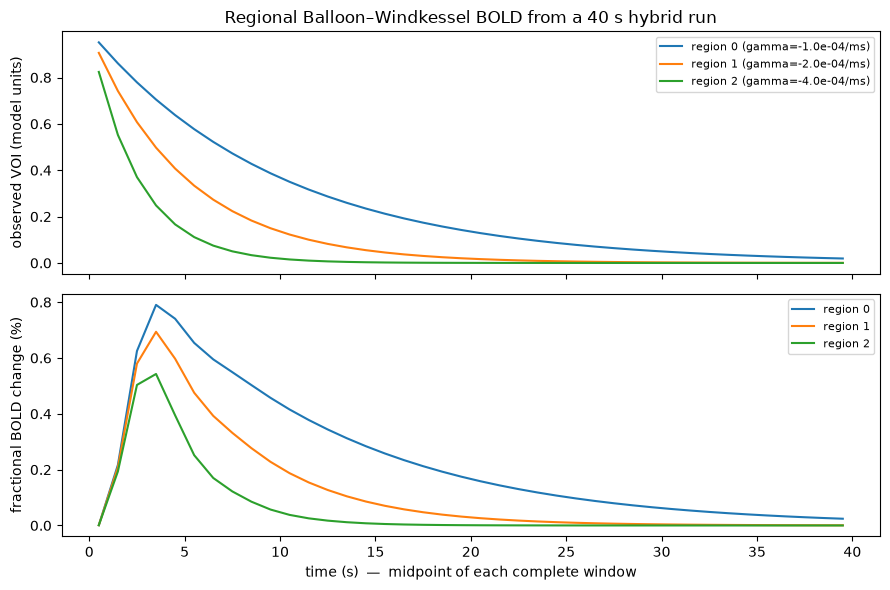

In [7]:
fig, (ax_neural, ax_bold) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
styles = ("C0", "C1", "C2")
for region, style in zip(range(3), styles):
    ax_neural.plot(neural_t / 1000.0, neural_x[:, 0, region, 0],
                   style, label=f"region {region} (gamma={GAMMA[region]:.1e}/ms)")
    ax_bold.plot(long_t / 1000.0, 100.0 * long_x[:, 0, region, 0],
                 style, label=f"region {region}")
ax_neural.set_ylabel("observed VOI (model units)")
ax_neural.set_title("Regional Balloon–Windkessel BOLD from a 40 s hybrid run")
ax_neural.legend(loc="upper right", fontsize=8)
ax_bold.set_xlabel("time (s)  —  midpoint of each complete window")
ax_bold.set_ylabel("fractional BOLD change (%)")
ax_bold.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

## 6. What this demo does and does not show

- The output is the balloon model's fractional BOLD change at window
  midpoints, in subnetwork-local region order, with one shared nominal
  hemodynamic parameter set applied independently per region.
- The drive is whatever you calibrate: `drive_baseline` and `drive_scale`
  are explicit, finite, and map the observed VOI window mean to `s⁻²`. There
  are no fitted population parameters and no per-region parameter lowering.
- Complete windows only: the last incomplete drive window, and any partial
  output period, are dropped instead of being flushed.
- This is a global monitor on one width-one regional subnetwork. Local
  `Recorder`-based BW monitors are not implemented at this baseline, and BW
  is not available in parameter sweeps.
- Resume is supported only from compatible compiled snapshots that keep the
  partial drive and BOLD windows; a failed run is not a whole-simulator
  rollback.